# Meeting 3 — Generating from training photos

**Question:** how close to the 15 real Egyptian Mau training photos should the synthetic images be?

In Meeting 2 the model only read a description. Here it also sees the training photos, in two ways:

| Mode | What the photo does | Setting swept |
|---|---|---|
| **img2img** | the starting point: noise is added to the photo and removed again | `--strength` 0.3, 0.5, 0.7, 0.9 (near 0: a copy; near 1: a new image) |
| **IP-Adapter** | a reference: the model draws a new image of a similar cat | `--ip-adapter-scale` 0.3, 0.5, 0.7, 1.0 (how strongly the photo steers) |

Both modes use the 15 training photos in turn (image *i* of every pool starts from photo *i* mod 15 with seed
1000 + *i*), so the pools are directly comparable. Only the 15 **training** photos are used; the tools refuse any other.
Everything else is as before: 110 images per pool, 55 added per seed, EfficientNet-B0, 5 seeds, choices on
validation, test only for the chosen runs.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image as ShowImage
from PIL import Image

from synthdata import generate, test, train
from synthdata.config import CLASSES, EVIDENCE_DIR, POOLS_DIR, RUNS_DIR, TARGET
from synthdata.data import minority_training_photos
from synthdata.inputs import source_photo

pd.set_option("display.width", 180)
EVIDENCE_DIR.mkdir(exist_ok=True)

STRENGTHS = [0.3, 0.5, 0.7, 0.9]
SCALES = [0.3, 0.5, 0.7, 1.0]
IMG2IMG = [f"m3-strength-{s}" for s in STRENGTHS]
IPADAPTER = [f"m3-ip-{s}" for s in SCALES]
POOLS = IMG2IMG + IPADAPTER
REFERENCE = ["m1-oversample", "m1-augment", "m2-prompts-varied"]

## 1. Prompt and source photos

Both modes still need a prompt, and it stays the same within each sweep so that only the strength or the scale changes.
I use the **Meeting 2 base prompt**:

> *a photo of an Egyptian Mau cat, silver coat with random dark spots, green eyes, at home*

The pool taken forward from Meeting 2 (`m2-prompts-varied`) used four prompts that describe specific scenes and coats
("lying on a sofa", "bronze coat", …). Together with a real photo they would contradict it — img2img keeps the photo's
pose and background, so "a bronze cat in a garden" on a photo of a silver cat on a chair fights the source. The base
prompt only describes the breed, so the photo decides the rest. It is the prompt of five of the six Meeting 2 pools.

The 15 source photos:

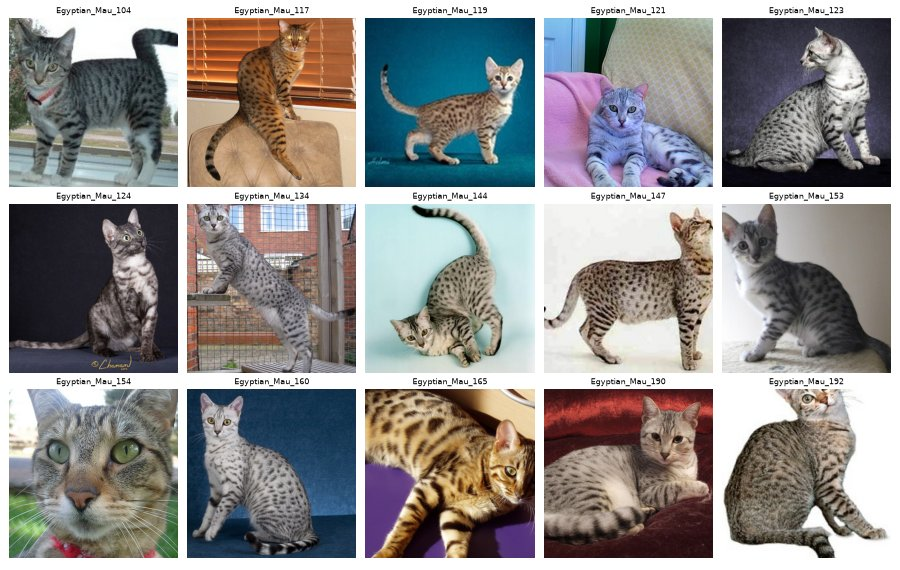

In [2]:
sources = minority_training_photos()
path = EVIDENCE_DIR / "m3-sources.jpg"
fig, axes = plt.subplots(3, 5, figsize=(15, 9.5))
for ax, name in zip(axes.flat, sources):
    ax.imshow(source_photo(name))
    ax.set_title(name, fontsize=9)
    ax.axis("off")
fig.tight_layout()
fig.savefig(path, dpi=60, pil_kwargs={"quality": 85})
plt.close(fig)
display(ShowImage(filename=str(path), width=900))

Most of them are **cat-show studio photos** (plain coloured backdrops: 119, 123, 124, 160; white cut-outs: 147,
192); only a few are ordinary home photos. Two carry a **photographer's signature** (Egyptian_Mau_124 "©Chanan" at the
bottom, Egyptian_Mau_119 a small mark bottom right), and Egyptian_Mau_144 shows two cats.

## 2. Generating the pools

```bash
P="<base prompt>"
uv run synth-generate --name m3-strength-0.3 --mode img2img --strength 0.3 --prompt "$P"   # also 0.5, 0.7, 0.9
uv run synth-generate --name m3-ip-0.3 --mode ip-adapter --ip-adapter-scale 0.3 --prompt "$P"   # also 0.5, 0.7, 1.0
```

A pool is generated only if it does not exist yet (the images are not in Git; manifests and contact sheets are).

In [3]:
PROMPT = 'a photo of an Egyptian Mau cat, silver coat with random dark spots, green eyes, at home'
for s in STRENGTHS:
    if not (POOLS_DIR / f"m3-strength-{s}" / "manifest.jsonl").exists():
        generate.main(["--name", f"m3-strength-{s}", "--mode", "img2img", "--strength", str(s), "--prompt", PROMPT])
for s in SCALES:
    if not (POOLS_DIR / f"m3-ip-{s}" / "manifest.jsonl").exists():
        generate.main(["--name", f"m3-ip-{s}", "--mode", "ip-adapter", "--ip-adapter-scale", str(s),
                       "--prompt", PROMPT])
print("all pools present")

all pools present


In [4]:
def manifest(pool):
    return [json.loads(line) for line in (POOLS_DIR / pool / "manifest.jsonl").read_text().splitlines() if line]


rows = []
for pool in POOLS:
    records = manifest(pool)
    rows.append({
        "pool": pool,
        "attempts": len(records),
        "usable": sum(r["status"] == "ok" for r in records),
        "safety-blocked": sum(r["status"] == "safety_blocked" for r in records),
        "effective steps": records[0]["effective_steps"],
        "source photos used": len({r["source"] for r in records}),
        "generation time (s)": round(sum(r["seconds"] for r in records)),
        "peak GPU memory (MB)": max(r["peak_vram_mb"] or 0 for r in records),
    })
pd.DataFrame(rows).set_index("pool")

,attempts,usable,safety-blocked,effective steps,source photos used,generation time (s),peak GPU memory (MB)
pool,,,,,,,
m3-strength-0.3,110,110,0,9,15,44,3258
m3-strength-0.5,110,110,0,15,15,65,3258
m3-strength-0.7,110,110,0,21,15,83,3258
m3-strength-0.9,110,110,0,27,15,107,3258
m3-ip-0.3,110,110,0,30,15,117,4512
m3-ip-0.5,110,110,0,30,15,136,4512
m3-ip-0.7,110,109,1,30,15,141,4512
m3-ip-1.0,110,107,3,30,15,141,4512


img2img runs only steps × strength denoising steps (9 at strength 0.3, 27 at 0.9), so weak strengths are also
cheaper; IP-Adapter always runs all 30 steps and needs about 1.2 GB more GPU memory. IP-Adapter at high scales had a few
safety-blocked attempts (1 at 0.7, 3 at 1.0); they stay in the manifests.

## 3. Contact sheets: every image next to its source photo

m3-strength-0.3


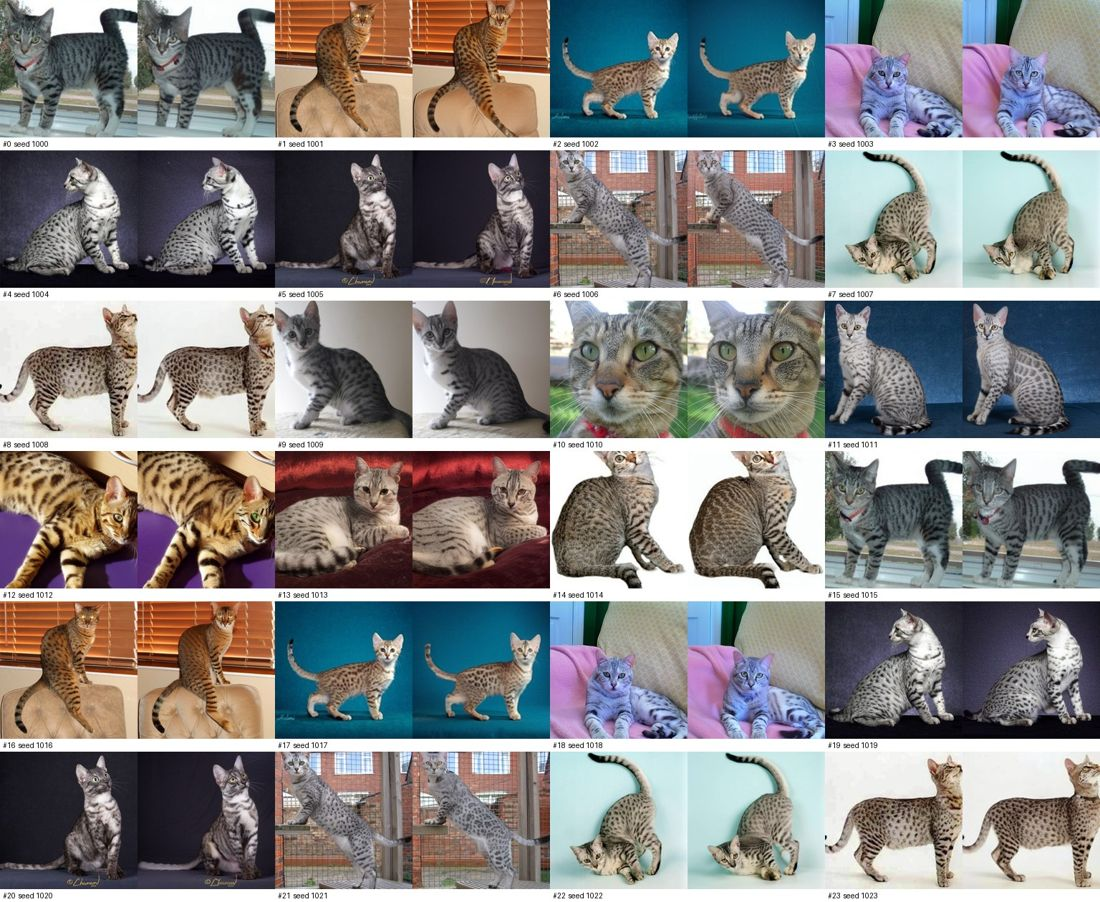

m3-strength-0.5


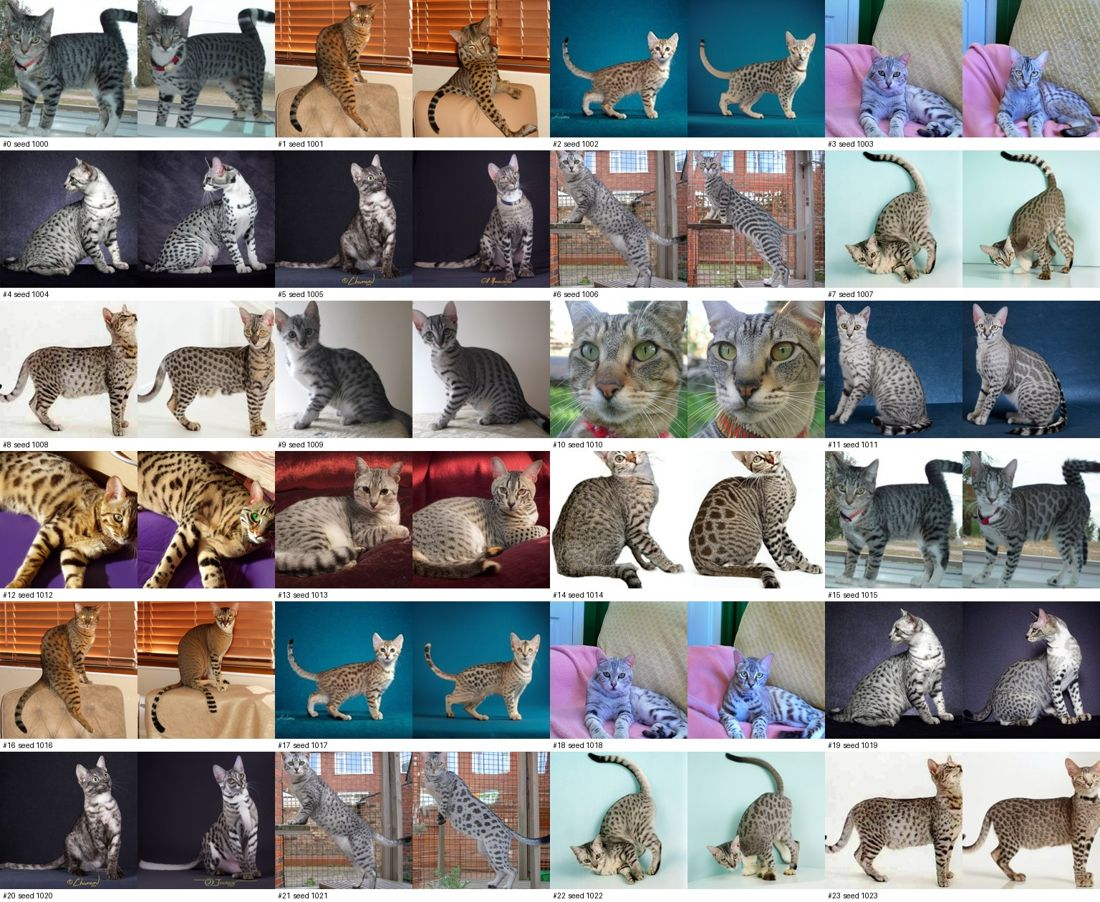

m3-strength-0.7


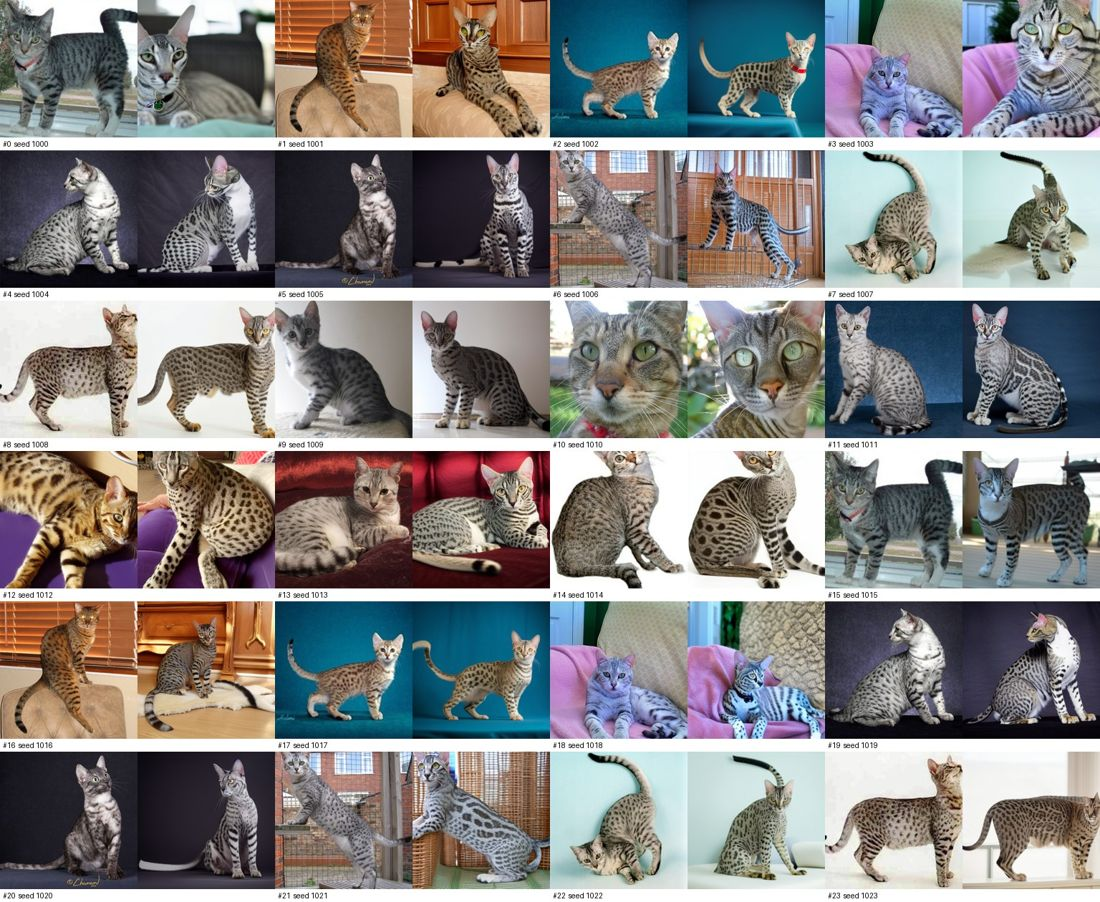

m3-strength-0.9


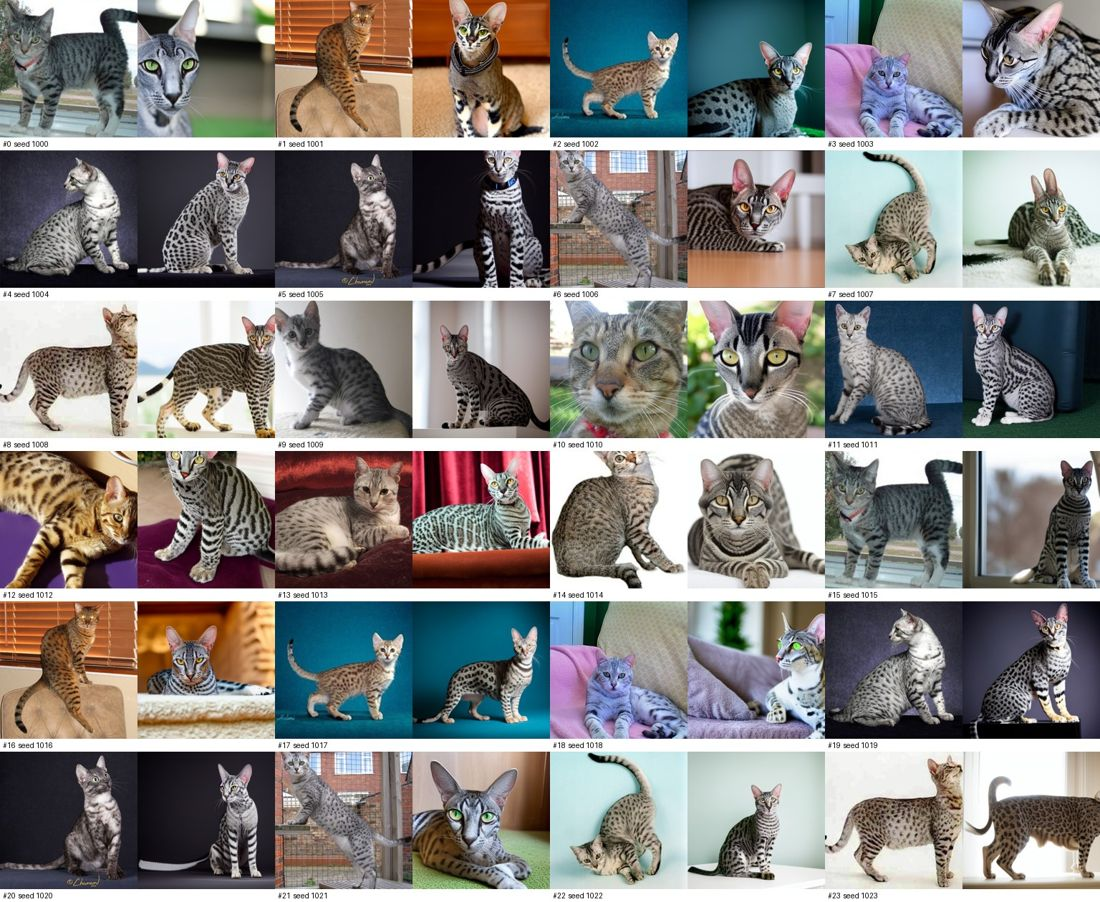

m3-ip-0.3


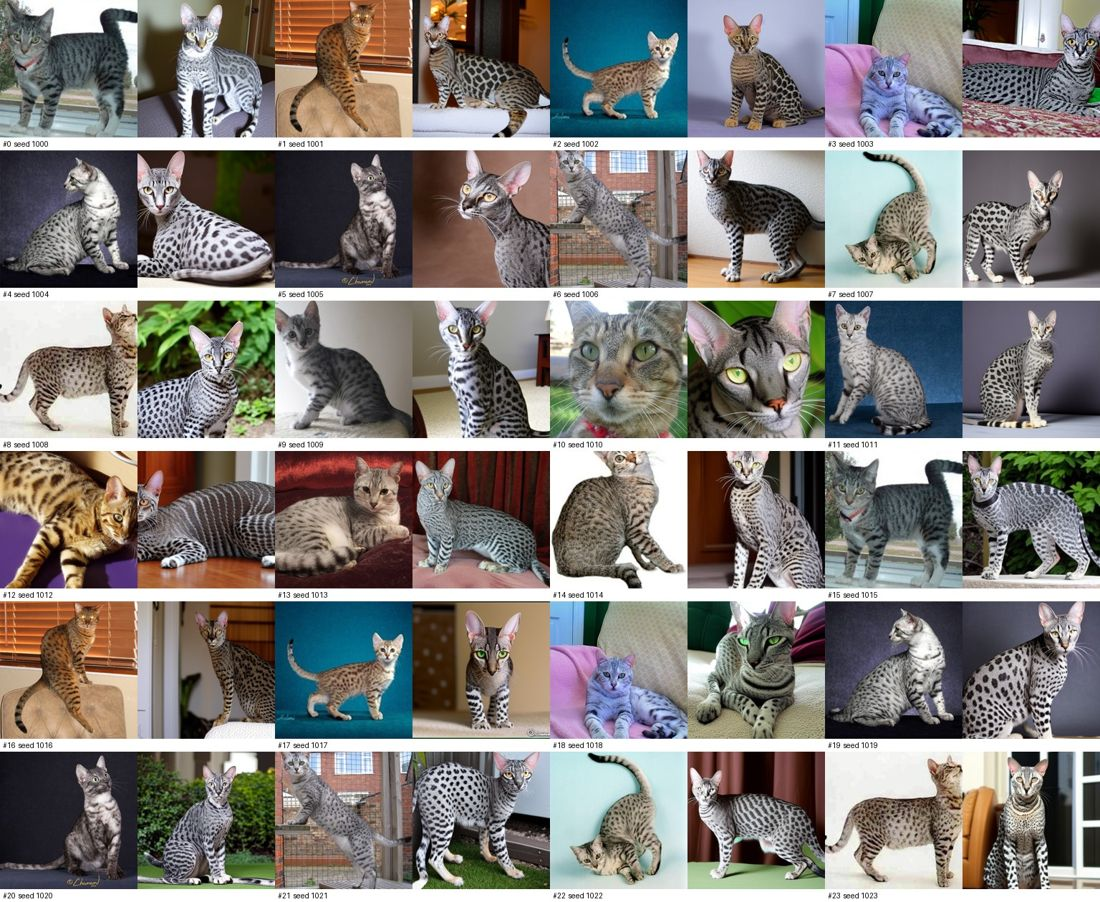

m3-ip-0.5


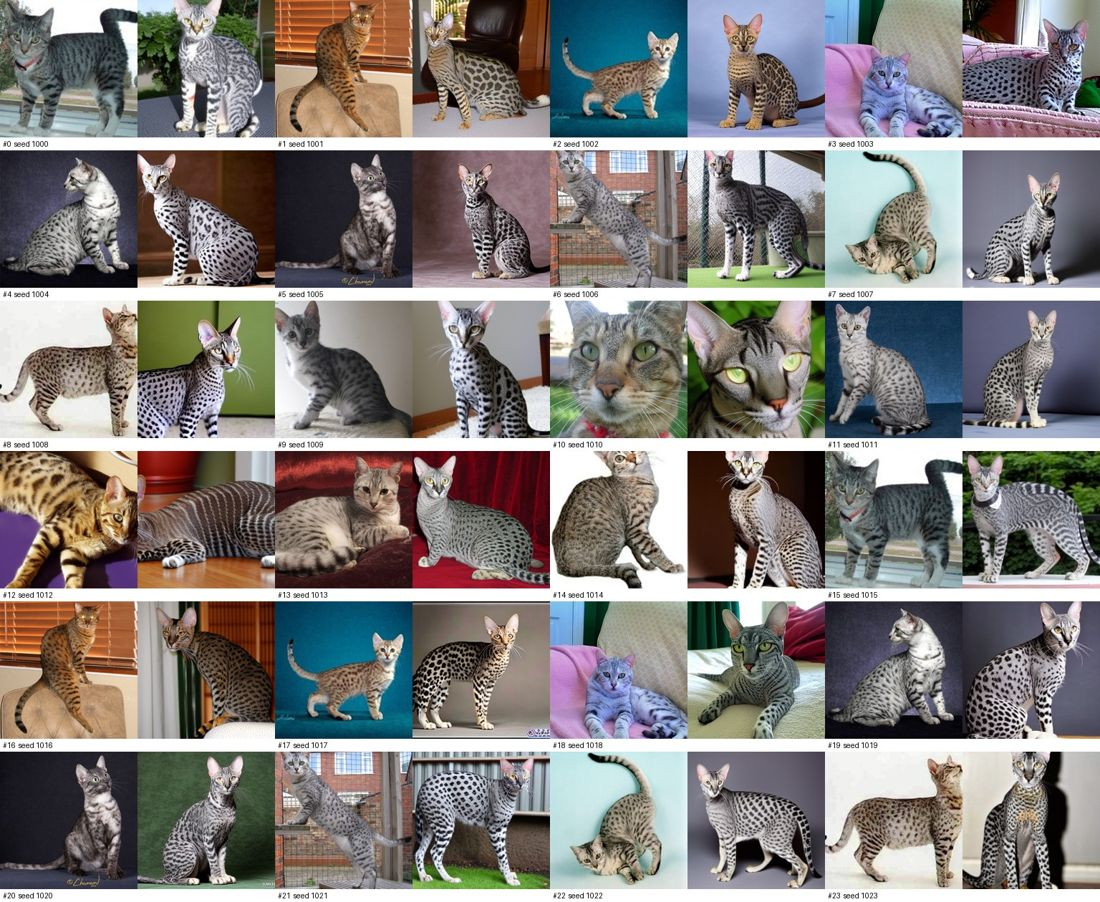

m3-ip-0.7


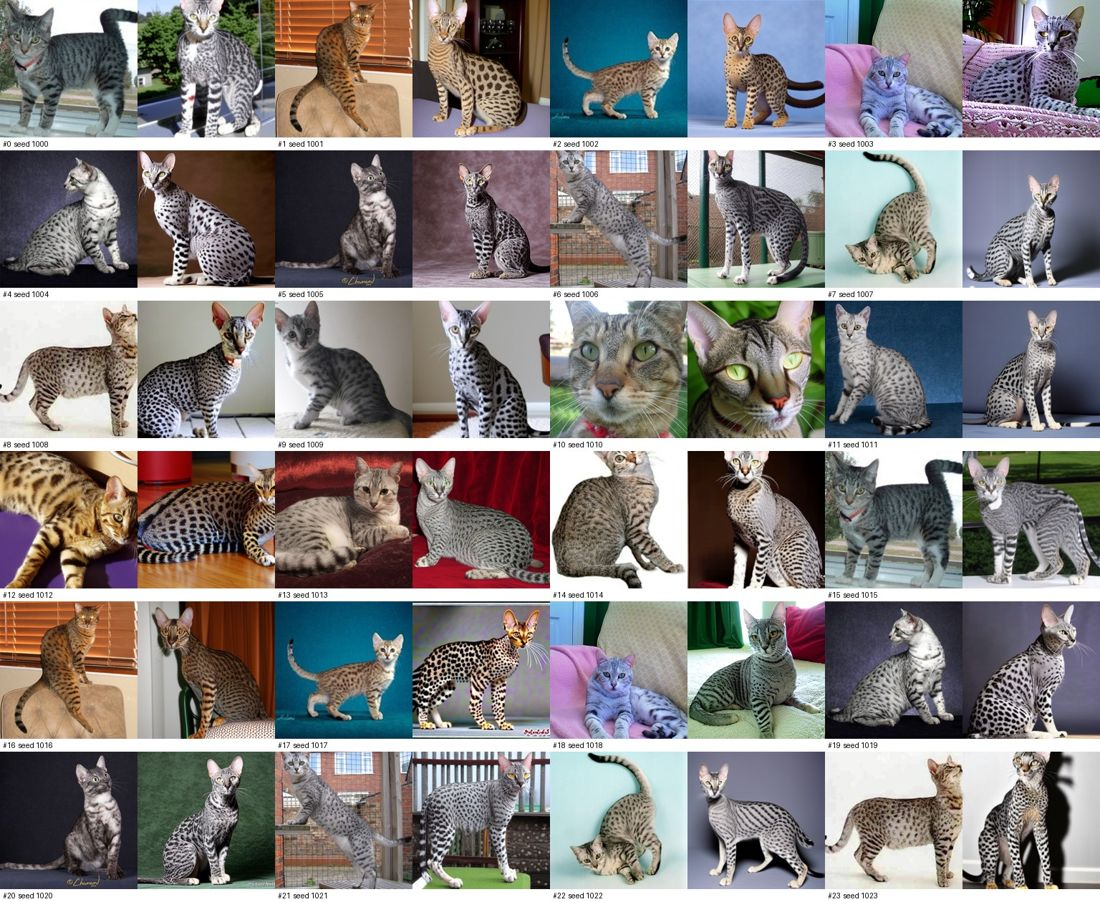

m3-ip-1.0


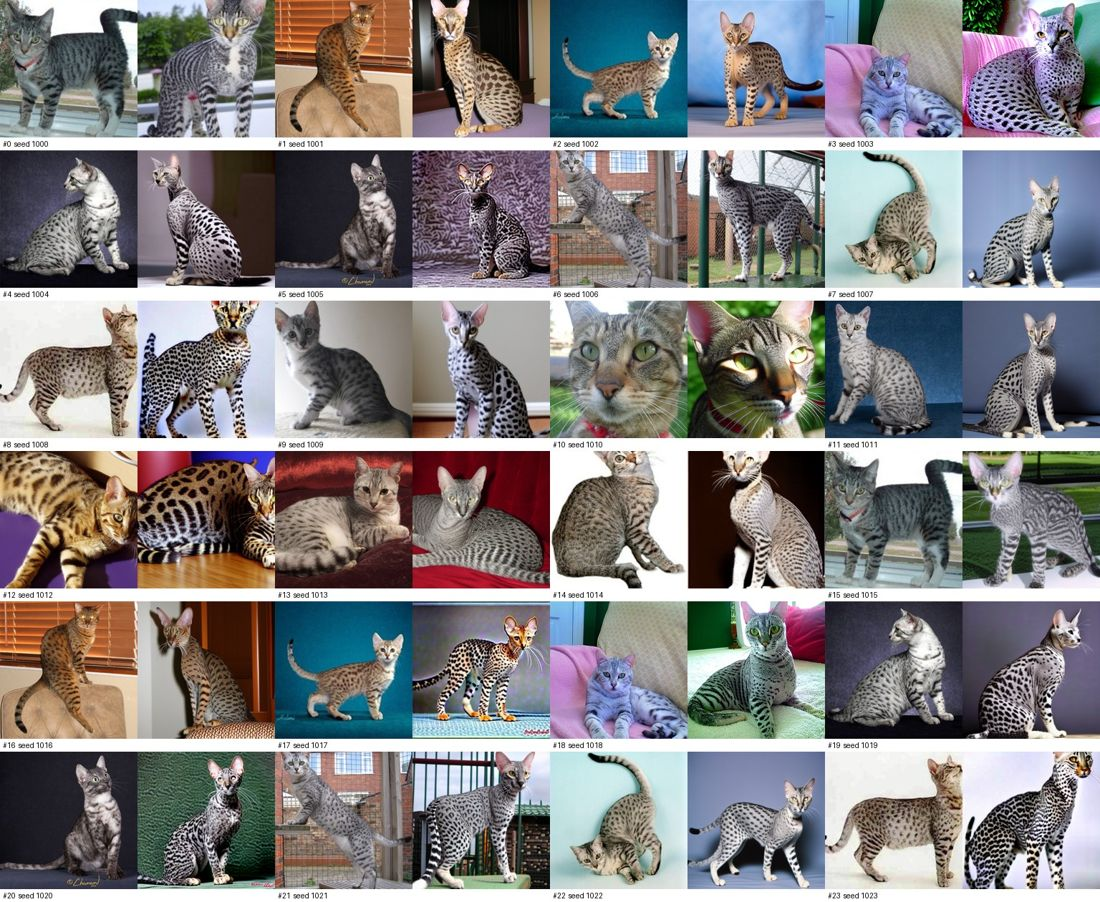

In [5]:
import io


def show_small(path, width=1100):
    """Embed a smaller copy so the notebook stays light; the full sheet stays in pools/."""
    image = Image.open(path)
    image = image.resize((width, round(image.height * width / image.width)))
    buffer = io.BytesIO()
    image.save(buffer, format="JPEG", quality=80)
    display(ShowImage(data=buffer.getvalue(), width=950))


for pool in POOLS:
    print(pool)
    show_small(POOLS_DIR / pool / "contact-sheet.jpg")

### The same source photo across both sweeps

Each pair of rows starts from the same training photo (and the same seed): first the four img2img strengths, then the
four IP-Adapter scales.

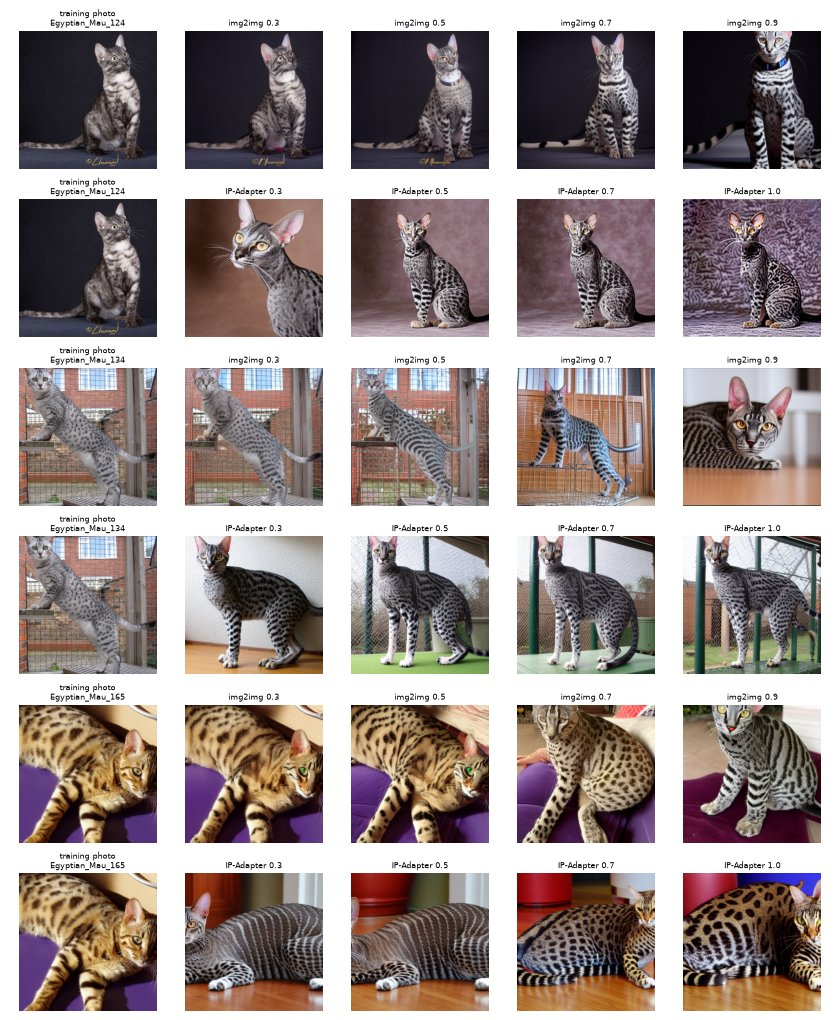

In [6]:
EXAMPLE_INDICES = [5, 6, 12]   # Egyptian_Mau_124 (signature), _134, _165 (bronze)


def pool_image(pool, index):
    return Image.open(POOLS_DIR / pool / "images" / f"{pool}-{index:04d}.png")


path = EVIDENCE_DIR / "m3-examples.jpg"
if all((POOLS_DIR / p / "images" / f"{p}-{i:04d}.png").exists() for p in POOLS for i in EXAMPLE_INDICES):
    fig, axes = plt.subplots(2 * len(EXAMPLE_INDICES), 5, figsize=(14, 17))
    for k, index in enumerate(EXAMPLE_INDICES):
        source = manifest(IMG2IMG[0])[index]["source"]
        for r, (mode, pools, values) in enumerate([("img2img", IMG2IMG, STRENGTHS),
                                                    ("IP-Adapter", IPADAPTER, SCALES)]):
            row = axes[2 * k + r]
            row[0].imshow(source_photo(source))
            row[0].set_title(f"training photo\n{source}", fontsize=9)
            for ax, pool, value in zip(row[1:], pools, values):
                ax.imshow(pool_image(pool, index))
                ax.set_title(f"{mode} {value}", fontsize=9)
            for ax in row:
                ax.axis("off")
    fig.tight_layout()
    fig.savefig(path, dpi=60, pil_kwargs={"quality": 85})
    plt.close(fig)
display(ShowImage(filename=str(path), width=900))

What the contact sheets show:

* **img2img 0.3 — near copies.** Pose, background, coat and colour are those of the photo, only slightly smoothed. The
  photographer's signature is copied too (Egyptian_Mau_124: "©Chanan" in #5 and #20; a small mark in #2 and #17).
* **img2img 0.5** keeps pose and background but redraws the cat: the spots become larger and sharper, sometimes
  leopard-like blotches (#14, #21); the signature is still there, distorted into a scribble (#5, #20).
* **img2img 0.7** keeps the rough pose and the background colours, but the cat is redrawn in Stable Diffusion's own
  style: spots partly turn into stripes or blotches (#11, #15, #21), ears grow, bronze photos become silver cats (#1,
  #12). The signature disappears.
* **img2img 0.9** — essentially new images like the Meeting 2 base pool (close-ups, big ears, striped coats: #9, #12,
  #13); the photo contributes only the background tone (the dark studio backdrops in #4, #5, #19, #20).
* **IP-Adapter 0.3** draws new poses and scenes; the coat is clearly *spotted* more often than in the text-only pools.
  The source's colour comes through only sometimes (bronze cats in #1, #2); often the prompt's "silver" wins (the
  bronze Egyptian_Mau_165 above becomes a silver cat at 0.3 and 0.5). Some spots become dalmatian-like (#4, #21).
* **IP-Adapter 0.5 – 1.0** moves towards the source photo's look: its backdrop colours (blue, purple, pink), lighting
  and even the scene (the fence of Egyptian_Mau_134 above) are copied, while the pose stays new; the spots get denser and
  darker (dalmatian-like: #4, #8, #17, #21), signature-like marks appear (#17 bottom right, #20 at 0.5), and at 1.0 the
  images degrade into over-sharpened, noisy textures (#5, #17).

## 4. Training

```bash
uv run synth-train --name m3-strength-0.3 --method synthetic --pool m3-strength-0.3 --tag mode=img2img --tag strength=0.3
uv run synth-train --name m3-ip-0.3 --method synthetic --pool m3-ip-0.3 --tag mode=ip-adapter --tag scale=0.3
# … and the same for the other strengths and scales
```

In [7]:
for s, pool in zip(STRENGTHS, IMG2IMG):
    train.main(["--name", pool, "--method", "synthetic", "--pool", pool,
                "--tag", "mode=img2img", "--tag", f"strength={s}"])
for s, pool in zip(SCALES, IPADAPTER):
    train.main(["--name", pool, "--method", "synthetic", "--pool", pool,
                "--tag", "mode=ip-adapter", "--tag", f"scale={s}"])

m3-strength-0.3: synthetic, efficientnet_b0, 5 seeds, cuda
  seed 0: already done
  seed 1: already done
  seed 2: already done
  seed 3: already done
  seed 4: already done
Results of every seed are in D:\PROJEKTY\STUDIA\Syntetyczne dane (projekt) - synthetic-cats-benchmark\runs\m3-strength-0.3\results.json


m3-strength-0.5: synthetic, efficientnet_b0, 5 seeds, cuda
  seed 0: already done
  seed 1: already done
  seed 2: already done
  seed 3: already done
  seed 4: already done
Results of every seed are in D:\PROJEKTY\STUDIA\Syntetyczne dane (projekt) - synthetic-cats-benchmark\runs\m3-strength-0.5\results.json


m3-strength-0.7: synthetic, efficientnet_b0, 5 seeds, cuda
  seed 0: already done
  seed 1: already done
  seed 2: already done
  seed 3: already done
  seed 4: already done
Results of every seed are in D:\PROJEKTY\STUDIA\Syntetyczne dane (projekt) - synthetic-cats-benchmark\runs\m3-strength-0.7\results.json


m3-strength-0.9: synthetic, efficientnet_b0, 5 seeds, cuda
  seed 0: already done
  seed 1: already done
  seed 2: already done
  seed 3: already done
  seed 4: already done
Results of every seed are in D:\PROJEKTY\STUDIA\Syntetyczne dane (projekt) - synthetic-cats-benchmark\runs\m3-strength-0.9\results.json


m3-ip-0.3: synthetic, efficientnet_b0, 5 seeds, cuda
  seed 0: already done
  seed 1: already done
  seed 2: already done
  seed 3: already done
  seed 4: already done
Results of every seed are in D:\PROJEKTY\STUDIA\Syntetyczne dane (projekt) - synthetic-cats-benchmark\runs\m3-ip-0.3\results.json


m3-ip-0.5: synthetic, efficientnet_b0, 5 seeds, cuda
  seed 0: already done
  seed 1: already done
  seed 2: already done
  seed 3: already done
  seed 4: already done
Results of every seed are in D:\PROJEKTY\STUDIA\Syntetyczne dane (projekt) - synthetic-cats-benchmark\runs\m3-ip-0.5\results.json


m3-ip-0.7: synthetic, efficientnet_b0, 5 seeds, cuda
  seed 0: already done
  seed 1: already done
  seed 2: already done
  seed 3: already done
  seed 4: already done
Results of every seed are in D:\PROJEKTY\STUDIA\Syntetyczne dane (projekt) - synthetic-cats-benchmark\runs\m3-ip-0.7\results.json


m3-ip-1.0: synthetic, efficientnet_b0, 5 seeds, cuda
  seed 0: already done
  seed 1: already done
  seed 2: already done
  seed 3: already done
  seed 4: already done
Results of every seed are in D:\PROJEKTY\STUDIA\Syntetyczne dane (projekt) - synthetic-cats-benchmark\runs\m3-ip-1.0\results.json


## 5. Validation results (every seed)

20 Egyptian Mau validation photos, one photo = 0.05. The Meeting 1 baselines and the Meeting 2 pool are included.

In [8]:
def load_results(runs, filename="results.json"):
    rows = []
    for run in runs:
        data = json.loads((RUNS_DIR / run / filename).read_text())
        for s in data["seeds"]:
            rows.append({"run": run, **data.get("tags", {}), "seed": s["seed"],
                         "egyptian_mau_recall": s["egyptian_mau_recall"], "macro_f1": s["macro_f1"],
                         **{f"recall {b}": s["recall"][b] for b in CLASSES}})
    return pd.DataFrame(rows)


def seed_table(results, runs):
    tables = []
    for metric in ["egyptian_mau_recall", "macro_f1"]:
        wide = results.pivot(index="seed", columns="run", values=metric)[runs]
        wide.loc["mean"] = wide.loc[0:4].mean()
        wide.loc["std"] = wide.loc[0:4].std()
        tables.append(wide.T.add_prefix(f"{metric} | "))
    return pd.concat(tables, axis=1)


RUNS = REFERENCE + POOLS
val = load_results(RUNS)
val_table = seed_table(val, RUNS)
val_table.round(3).to_csv(EVIDENCE_DIR / "m3-validation.csv")
val_table.round(3)

seed,egyptian_mau_recall | 0,egyptian_mau_recall | 1,egyptian_mau_recall | 2,egyptian_mau_recall | 3,egyptian_mau_recall | 4,egyptian_mau_recall | mean,egyptian_mau_recall | std,macro_f1 | 0,macro_f1 | 1,macro_f1 | 2,macro_f1 | 3,macro_f1 | 4,macro_f1 | mean,macro_f1 | std
run,,,,,,,,,,,,,,
m1-oversample,0.65,0.60,0.65,0.75,0.70,0.67,0.057,0.885,0.878,0.885,0.912,0.911,0.894,0.016
m1-augment,0.70,0.70,0.70,0.85,0.70,0.73,0.067,0.886,0.861,0.879,0.905,0.898,0.886,0.017
m2-prompts-varied,0.75,0.75,0.75,0.90,0.80,0.79,0.065,0.905,0.875,0.899,0.913,0.918,0.902,0.017
m3-strength-0.3,0.75,0.65,0.75,0.80,0.75,0.74,0.055,0.899,0.880,0.887,0.900,0.899,0.893,0.009
m3-strength-0.5,0.85,0.65,0.75,0.80,0.80,0.77,0.076,0.919,0.879,0.899,0.906,0.912,0.903,0.015
m3-strength-0.7,0.85,0.75,0.75,0.85,0.80,0.80,0.050,0.919,0.881,0.899,0.913,0.918,0.906,0.016
m3-strength-0.9,0.80,0.80,0.75,0.85,0.80,0.80,0.035,0.924,0.888,0.893,0.907,0.912,0.905,0.015
m3-ip-0.3,0.80,0.75,0.65,0.80,0.75,0.75,0.061,0.912,0.875,0.879,0.900,0.906,0.895,0.016
m3-ip-0.5,0.75,0.65,0.65,0.80,0.70,0.71,0.065,0.899,0.874,0.892,0.900,0.905,0.894,0.012


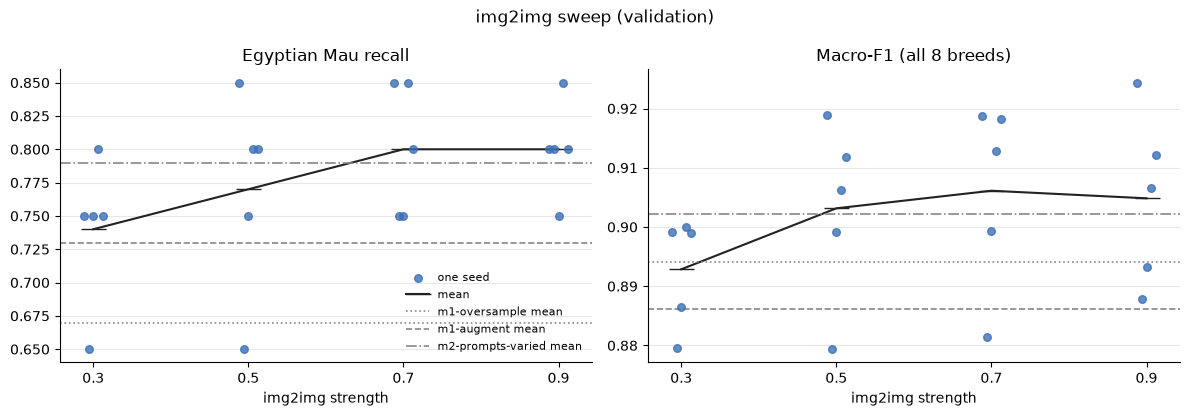

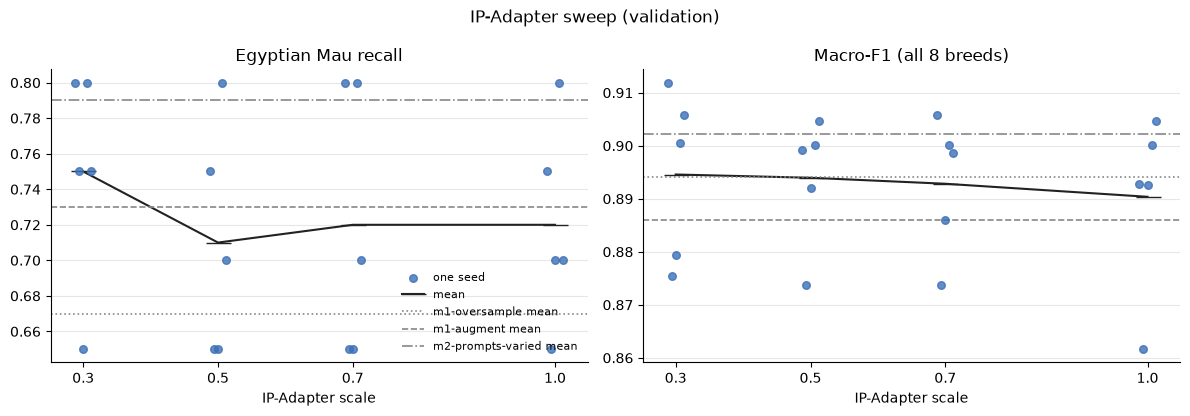

In [9]:
BLUE, GREY = "#3b6fb6", "#888888"
METRICS = [("egyptian_mau_recall", "Egyptian Mau recall"), ("macro_f1", "Macro-F1 (all 8 breeds)")]
reference_means = val[val.run.isin(REFERENCE)].groupby("run")[["egyptian_mau_recall", "macro_f1"]].mean()


def sweep_plot(runs, setting, values, title, path):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
    for ax, (metric, label) in zip(axes, METRICS):
        means = []
        for value, run in zip(values, runs):
            seeds = val.loc[val.run == run, metric].to_numpy()
            ax.scatter(value + np.linspace(-0.012, 0.012, len(seeds)), seeds, s=30, color=BLUE, alpha=0.8,
                       zorder=3, label="one seed" if value == values[0] else None)
            means.append(seeds.mean())
        ax.plot(values, means, color="#222222", marker="_", markersize=18, lw=1.5, zorder=2, label="mean")
        for run, style in [("m1-oversample", ":"), ("m1-augment", "--"), ("m2-prompts-varied", "-.")]:
            ax.axhline(reference_means.loc[run, metric], color=GREY, ls=style, lw=1.2, label=f"{run} mean")
        ax.set_xticks(values)
        ax.set_xlabel(setting)
        ax.set_title(label)
        ax.grid(axis="y", alpha=0.3)
        ax.spines[["top", "right"]].set_visible(False)
    axes[0].legend(frameon=False, fontsize=8, loc="lower right")
    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(path, dpi=100)
    plt.show()


sweep_plot(IMG2IMG, "img2img strength", STRENGTHS, "img2img sweep (validation)", EVIDENCE_DIR / "m3-img2img.png")
sweep_plot(IPADAPTER, "IP-Adapter scale", SCALES, "IP-Adapter sweep (validation)", EVIDENCE_DIR / "m3-ip-adapter.png")

### Where do the Egyptian Mau mistakes go — and does it cost Bengal?

Summed over the 5 seeds (100 predictions of Egyptian Mau photos per run).

In [10]:
def confusion(run, filename="metrics.json"):
    return sum(np.array(json.loads((RUNS_DIR / run / f"seed-{k}" / filename).read_text())["confusion"])
               for k in range(5))


def mau_mistakes(runs, filename="metrics.json"):
    i, b = CLASSES.index(TARGET), CLASSES.index("Bengal")
    rows = {}
    for run in runs:
        total = confusion(run, filename)
        rows[run] = {**dict(zip(CLASSES, total[i])), "Bengal predicted as Egyptian Mau": total[b, i],
                     "all predictions of Egyptian Mau": total[:, i].sum()}
    table = pd.DataFrame(rows).T
    return table.loc[:, table.sum() > 0]


def breed_recall(results):
    table = results.groupby("run", sort=False)[[f"recall {b}" for b in CLASSES]].mean()
    table.columns = CLASSES
    return table.round(2)


display(mau_mistakes(RUNS))
display(breed_recall(val))

,Abyssinian,Bengal,Egyptian Mau,Ragdoll,Russian Blue,Bengal predicted as Egyptian Mau,all predictions of Egyptian Mau
m1-oversample,10,12,67,1,10,6,73
m1-augment,10,10,73,0,7,12,85
m2-prompts-varied,5,9,79,0,7,4,83
m3-strength-0.3,10,10,74,0,6,7,81
m3-strength-0.5,10,8,77,0,5,6,83
m3-strength-0.7,9,8,80,0,3,5,85
m3-strength-0.9,6,10,80,0,4,5,85
m3-ip-0.3,9,11,75,0,5,4,79
m3-ip-0.5,10,11,71,0,8,2,73
m3-ip-0.7,9,13,72,0,6,2,74


,Abyssinian,Bengal,Birman,Bombay,Egyptian Mau,Ragdoll,Russian Blue,Siamese
run,,,,,,,,
m1-oversample,0.99,0.83,0.92,1.00,0.67,0.85,1.0,0.91
m1-augment,0.97,0.75,0.92,0.98,0.73,0.85,1.0,0.90
m2-prompts-varied,0.96,0.84,0.90,0.98,0.79,0.85,1.0,0.90
m3-strength-0.3,0.98,0.81,0.88,0.97,0.74,0.87,1.0,0.90
m3-strength-0.5,0.98,0.82,0.89,0.98,0.77,0.87,1.0,0.92
m3-strength-0.7,0.97,0.82,0.91,0.97,0.80,0.87,1.0,0.91
m3-strength-0.9,0.96,0.84,0.89,0.97,0.80,0.86,1.0,0.92
m3-ip-0.3,0.96,0.84,0.89,0.97,0.75,0.85,1.0,0.90
m3-ip-0.5,0.97,0.87,0.89,0.97,0.71,0.85,1.0,0.90


### What the validation results show

* **img2img: the further from the photo, the better** — Egyptian Mau recall rises from 0.74 (strength 0.3) to 0.77
  (0.5) and 0.80 (0.7 and 0.9). The near copies at 0.3 do about as well as augmentation (0.73), which they resemble:
  slightly changed versions of the same 15 photos. Each step on its own is within the seed spread (0.3: 0.65–0.80,
  0.7: 0.75–0.85), but the trend runs the same way across the whole sweep. Macro-F1 follows (0.893 → 0.906) and the
  Bengal cost stays small (5–7 of 100 Bengals called Egyptian Mau, against 12 with augmentation).
* **IP-Adapter: the weakest influence of the photo is best** — 0.75 at scale 0.3, then 0.71–0.72 at 0.5–1.0, i.e. at
  the level of augmentation and below the Meeting 2 pool (0.79). The models trained on these pools predict Egyptian
  Mau less often (73–79 times instead of 81–85): they are cautious, which keeps Bengal safe (Bengal recall 0.84–0.87,
  2–4 Bengals called Egyptian Mau) but misses more Egyptian Maus. Higher scales copy the studio-photo style of the
  sources and degrade the image quality, and that does not help.
* **Compared with Meeting 2:** the best img2img pools (0.80) are level with the text-only pool `m2-prompts-varied`
  (0.79); no IP-Adapter pool reaches it. Seeing the training photos therefore did not give better training images
  than the description alone; the best photo-based images (strength 0.7–0.9) are the ones that are closest to new
  text-to-image images.

### How close to the real photos should the synthetic images be?

**Not very close.** Near copies (img2img 0.3) add little that the 15 photos and ordinary augmentation do not already
give — the same pose, the same background, even the same photographer's signature — and they score like
augmentation. Images that keep only the rough layout and colours of a photo but redraw the cat (img2img 0.7) or are new
images altogether (0.9) help most. With IP-Adapter, a strong reference copies the *photo style* (studio backdrops,
lighting, signature-like marks) and degrades the images instead of adding variety, and the weakest reference (0.3) —
new poses and scenes, but a spotted, breed-like coat — works best. The useful part of the photos is therefore the
breed's appearance (spotted coat, colour), not their pose, background or style.

## 6. Choice (made on validation, before testing)

* **img2img: `m3-strength-0.7`.** It ties with strength 0.9 (both 0.80 mean recall, seed range 0.75–0.85, macro-F1
  0.906 vs 0.905), so the contact sheets decide: 0.7 still uses the training photo (rough layout and colours) while
  redrawing the cat, which is the point of this mode, whereas 0.9 hardly differs from the Meeting 2 text-only images.
  It is also cheaper (21 instead of 27 denoising steps).
* **IP-Adapter: `m3-ip-0.3`**, the best of its sweep (0.75 against 0.71–0.72), with the least degraded images.

Only these two runs are tested.

## 7. Test results, compared with Meetings 1 and 2

```bash
uv run synth-test --run m3-strength-0.7
uv run synth-test --run m3-ip-0.3
```

30 Egyptian Mau test photos, one photo = 0.033. A run is tested only once; if `test-results.json` exists, the cell
just reads it.

In [11]:
CHOSEN = ["m3-strength-0.7", "m3-ip-0.3"]
for run in CHOSEN:
    if (RUNS_DIR / run / "test-results.json").exists():
        print(f"{run}: already tested")
    else:
        test.main(["--run", run])

TESTED = ["m1-real", "m1-oversample", "m1-augment", "m2-prompts-varied"] + CHOSEN
test_results = load_results(TESTED, "test-results.json")
test_table = seed_table(test_results, TESTED)
test_table.round(3).to_csv(EVIDENCE_DIR / "m3-test.csv")
test_table.round(3)

m3-strength-0.7: already tested
m3-ip-0.3: already tested


seed,egyptian_mau_recall | 0,egyptian_mau_recall | 1,egyptian_mau_recall | 2,egyptian_mau_recall | 3,egyptian_mau_recall | 4,egyptian_mau_recall | mean,egyptian_mau_recall | std,macro_f1 | 0,macro_f1 | 1,macro_f1 | 2,macro_f1 | 3,macro_f1 | 4,macro_f1 | mean,macro_f1 | std
run,,,,,,,,,,,,,,
m1-real,0.433,0.533,0.500,0.433,0.633,0.507,0.083,0.846,0.858,0.865,0.846,0.868,0.857,0.010
m1-oversample,0.700,0.667,0.733,0.700,0.700,0.700,0.024,0.875,0.877,0.891,0.883,0.874,0.880,0.007
m1-augment,0.733,0.700,0.733,0.733,0.733,0.727,0.015,0.883,0.878,0.882,0.899,0.878,0.884,0.009
m2-prompts-varied,0.733,0.733,0.733,0.700,0.733,0.727,0.015,0.900,0.879,0.891,0.887,0.879,0.887,0.009
m3-strength-0.7,0.767,0.700,0.767,0.700,0.767,0.740,0.037,0.892,0.871,0.895,0.883,0.883,0.885,0.010
m3-ip-0.3,0.767,0.767,0.733,0.700,0.767,0.747,0.030,0.896,0.883,0.895,0.887,0.883,0.889,0.006


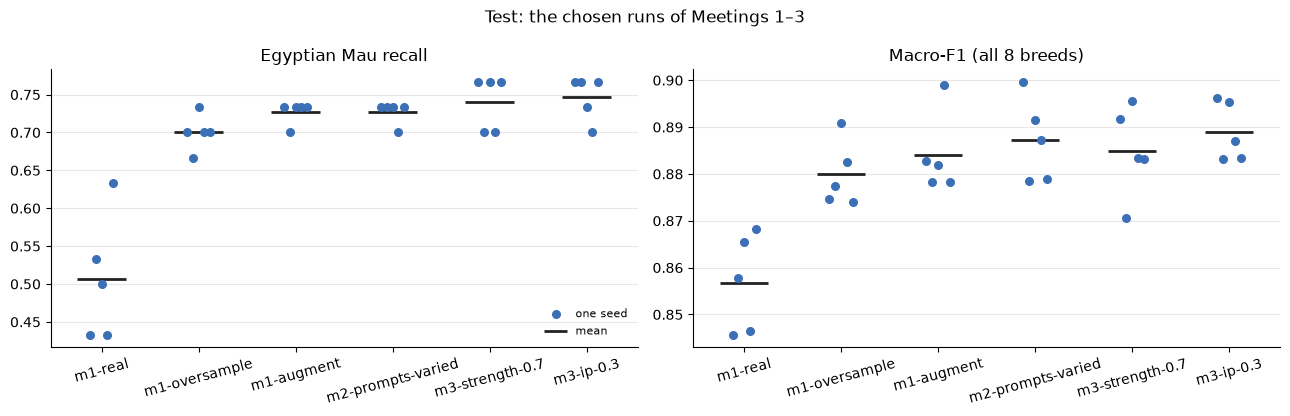

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, (metric, label) in zip(axes, METRICS):
    for x, run in enumerate(TESTED):
        seeds = test_results.loc[test_results.run == run, metric].to_numpy()
        ax.scatter(x + np.linspace(-0.12, 0.12, len(seeds)), seeds, s=30, color=BLUE, zorder=3,
                   label="one seed" if x == 0 else None)
        ax.hlines(seeds.mean(), x - 0.25, x + 0.25, color="#222222", lw=2, zorder=2,
                  label="mean" if x == 0 else None)
    ax.set_xticks(range(len(TESTED)), TESTED, rotation=15)
    ax.set_title(label)
    ax.grid(axis="y", alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].legend(frameon=False, fontsize=8, loc="lower right")
fig.suptitle("Test: the chosen runs of Meetings 1–3")
fig.tight_layout()
fig.savefig(EVIDENCE_DIR / "m3-test.png", dpi=100)

In [13]:
means = pd.DataFrame({
    "val Mau recall": load_results(TESTED).groupby("run")["egyptian_mau_recall"].mean(),
    "test Mau recall": test_results.groupby("run")["egyptian_mau_recall"].mean(),
    "val macro-F1": load_results(TESTED).groupby("run")["macro_f1"].mean(),
    "test macro-F1": test_results.groupby("run")["macro_f1"].mean(),
}).loc[TESTED]
display(means.round(3))
display(mau_mistakes(TESTED, "test-metrics.json"))
display(breed_recall(test_results))

,val Mau recall,test Mau recall,val macro-F1,test macro-F1
run,,,,
m1-real,0.49,0.507,0.857,0.857
m1-oversample,0.67,0.700,0.894,0.880
m1-augment,0.73,0.727,0.886,0.884
m2-prompts-varied,0.79,0.727,0.902,0.887
m3-strength-0.7,0.80,0.740,0.906,0.885
m3-ip-0.3,0.75,0.747,0.895,0.889


,Abyssinian,Bengal,Egyptian Mau,Russian Blue,Siamese,Bengal predicted as Egyptian Mau,all predictions of Egyptian Mau
m1-real,4,44,76,26,0,0,76
m1-oversample,6,20,105,18,1,1,106
m1-augment,6,20,109,14,1,7,117
m2-prompts-varied,5,24,109,12,0,0,110
m3-strength-0.7,5,24,111,10,0,3,115
m3-ip-0.3,5,24,112,8,1,0,113


,Abyssinian,Bengal,Birman,Bombay,Egyptian Mau,Ragdoll,Russian Blue,Siamese
run,,,,,,,,
m1-real,0.94,0.93,0.91,0.99,0.51,0.89,0.87,0.87
m1-oversample,0.92,0.90,0.91,0.97,0.70,0.88,0.85,0.91
m1-augment,0.93,0.86,0.91,0.99,0.73,0.88,0.87,0.91
m2-prompts-varied,0.91,0.92,0.91,0.97,0.73,0.90,0.86,0.90
m3-strength-0.7,0.91,0.89,0.91,0.97,0.74,0.89,0.87,0.90
m3-ip-0.3,0.91,0.91,0.91,0.97,0.75,0.90,0.85,0.90


### What the test results show

* **Egyptian Mau recall:** `m3-strength-0.7` reaches 0.740 and `m3-ip-0.3` 0.747 (both seeds 0.700–0.767, i.e. 21–23
  of 30 photos), against 0.727 for augmentation and for the Meeting 2 pool and 0.700 for oversampling. The differences
  to augmentation and Meeting 2 are 0.013 and 0.020 — less than one test photo — and the seed ranges overlap, so the
  photo-based images are **not clearly better** than augmentation or text-to-image on the test photos.
* **The validation ranking did not hold either way:** on validation `m3-ip-0.3` (0.75) was below the Meeting 2 pool
  (0.79) and `m3-strength-0.7` (0.80); on test it is marginally the highest. All of these runs are within one or two
  photos of each other on both splits.
* **Bengal:** neither run costs Bengal much — 0 (IP-Adapter) and 3 (img2img) of 150 Bengal test photos called
  Egyptian Mau, against 7 with augmentation; Bengal recall 0.91 and 0.89 (0.86 with augmentation). Macro-F1 is 0.889
  and 0.885, level with Meeting 2 (0.887) and augmentation (0.884). As before, the Egyptian Mau photos that are still
  missed are mostly called Bengal (24 of 150) and Russian Blue (8–10).